In [1]:
import numpy as np
import pandas as pd
import os
import glob
import matplotlib.pyplot as plt

In [2]:
# load 
df_all = pd.read_parquet('./STUV_0128_0514.parquet')

In [3]:
import matplotlib as mpl
from matplotlib import rcParams
## font manage
import matplotlib.font_manager as fm
font_path = '/gpfs01/euler/User/ydeng/Resource/Fonts/Arial.ttf'
font_prop = fm.FontProperties(fname=font_path)
fm.fontManager.addfont(font_path)
arial_font_name = font_prop.get_name()
print(f"Added font: {arial_font_name}")
rcParams['font.family'] = arial_font_name
rcParams['font.size'] = 9  # Common font size for all text
rcParams['svg.fonttype'] = 'none' # Ensure fonts are embedded as text, not converted to paths

Added font: Arial


In [4]:
rc_dict_boxplot = {'figure.dpi': 400,
                   'figure.figsize': [6, 4],
                   'figure.frameon': False,
                   'svg.fonttype':'none',
                   'font.family' :arial_font_name, 
    'font.size':9,
 'lines.markersize': 0.5,
 'lines.linewidth': .5,
 'lines.markeredgewidth': 0.5,
 'legend.columnspacing': 0.5,
 'legend.frameon': False,
 'legend.markerscale': 0.4,
 'legend.labelspacing': 0.1,
 'legend.handletextpad': 0,
 'legend.loc': 'lower right',
    'legend.fontsize': 9,
 'axes.labelpad': 1.0,
 'xtick.major.pad': 1,
 'ytick.major.pad': 1}

# Fig2D

In [5]:
import matplotlib as mpl
from matplotlib import rcParams
## font manage
import matplotlib.font_manager as fm
font_path = '/gpfs01/euler/User/ydeng/Resource/Fonts/Arial.ttf'
font_prop = fm.FontProperties(fname=font_path)
fm.fontManager.addfont(font_path)
arial_font_name = font_prop.get_name()
print(f"Added font: {arial_font_name}")
rcParams['font.family'] = arial_font_name
rcParams['font.size'] = 9  # Common font size for all text
rcParams['svg.fonttype'] = 'none' # Ensure fonts are embedded as text, not converted to paths

Added font: Arial


In [6]:
rc_dict_boxplot = {'figure.dpi': 400,
                   'figure.figsize': [6, 4],
                   'figure.frameon': False,
                   'svg.fonttype':'none',
                   'font.family' :arial_font_name, 
    'font.size':9,
 'lines.markersize': 0.5,
 'lines.linewidth': .5,
 'lines.markeredgewidth': 0.5,
 'legend.columnspacing': 0.5,
 'legend.frameon': False,
 'legend.markerscale': 0.4,
 'legend.labelspacing': 0.1,
 'legend.handletextpad': 0,
 'legend.loc': 'lower right',
    'legend.fontsize': 9,
 'axes.labelpad': 1.0,
 'xtick.major.pad': 1,
 'ytick.major.pad': 1}

In [7]:
bin_edges = np.linspace(0,30, 30) # xx equally spaced bins

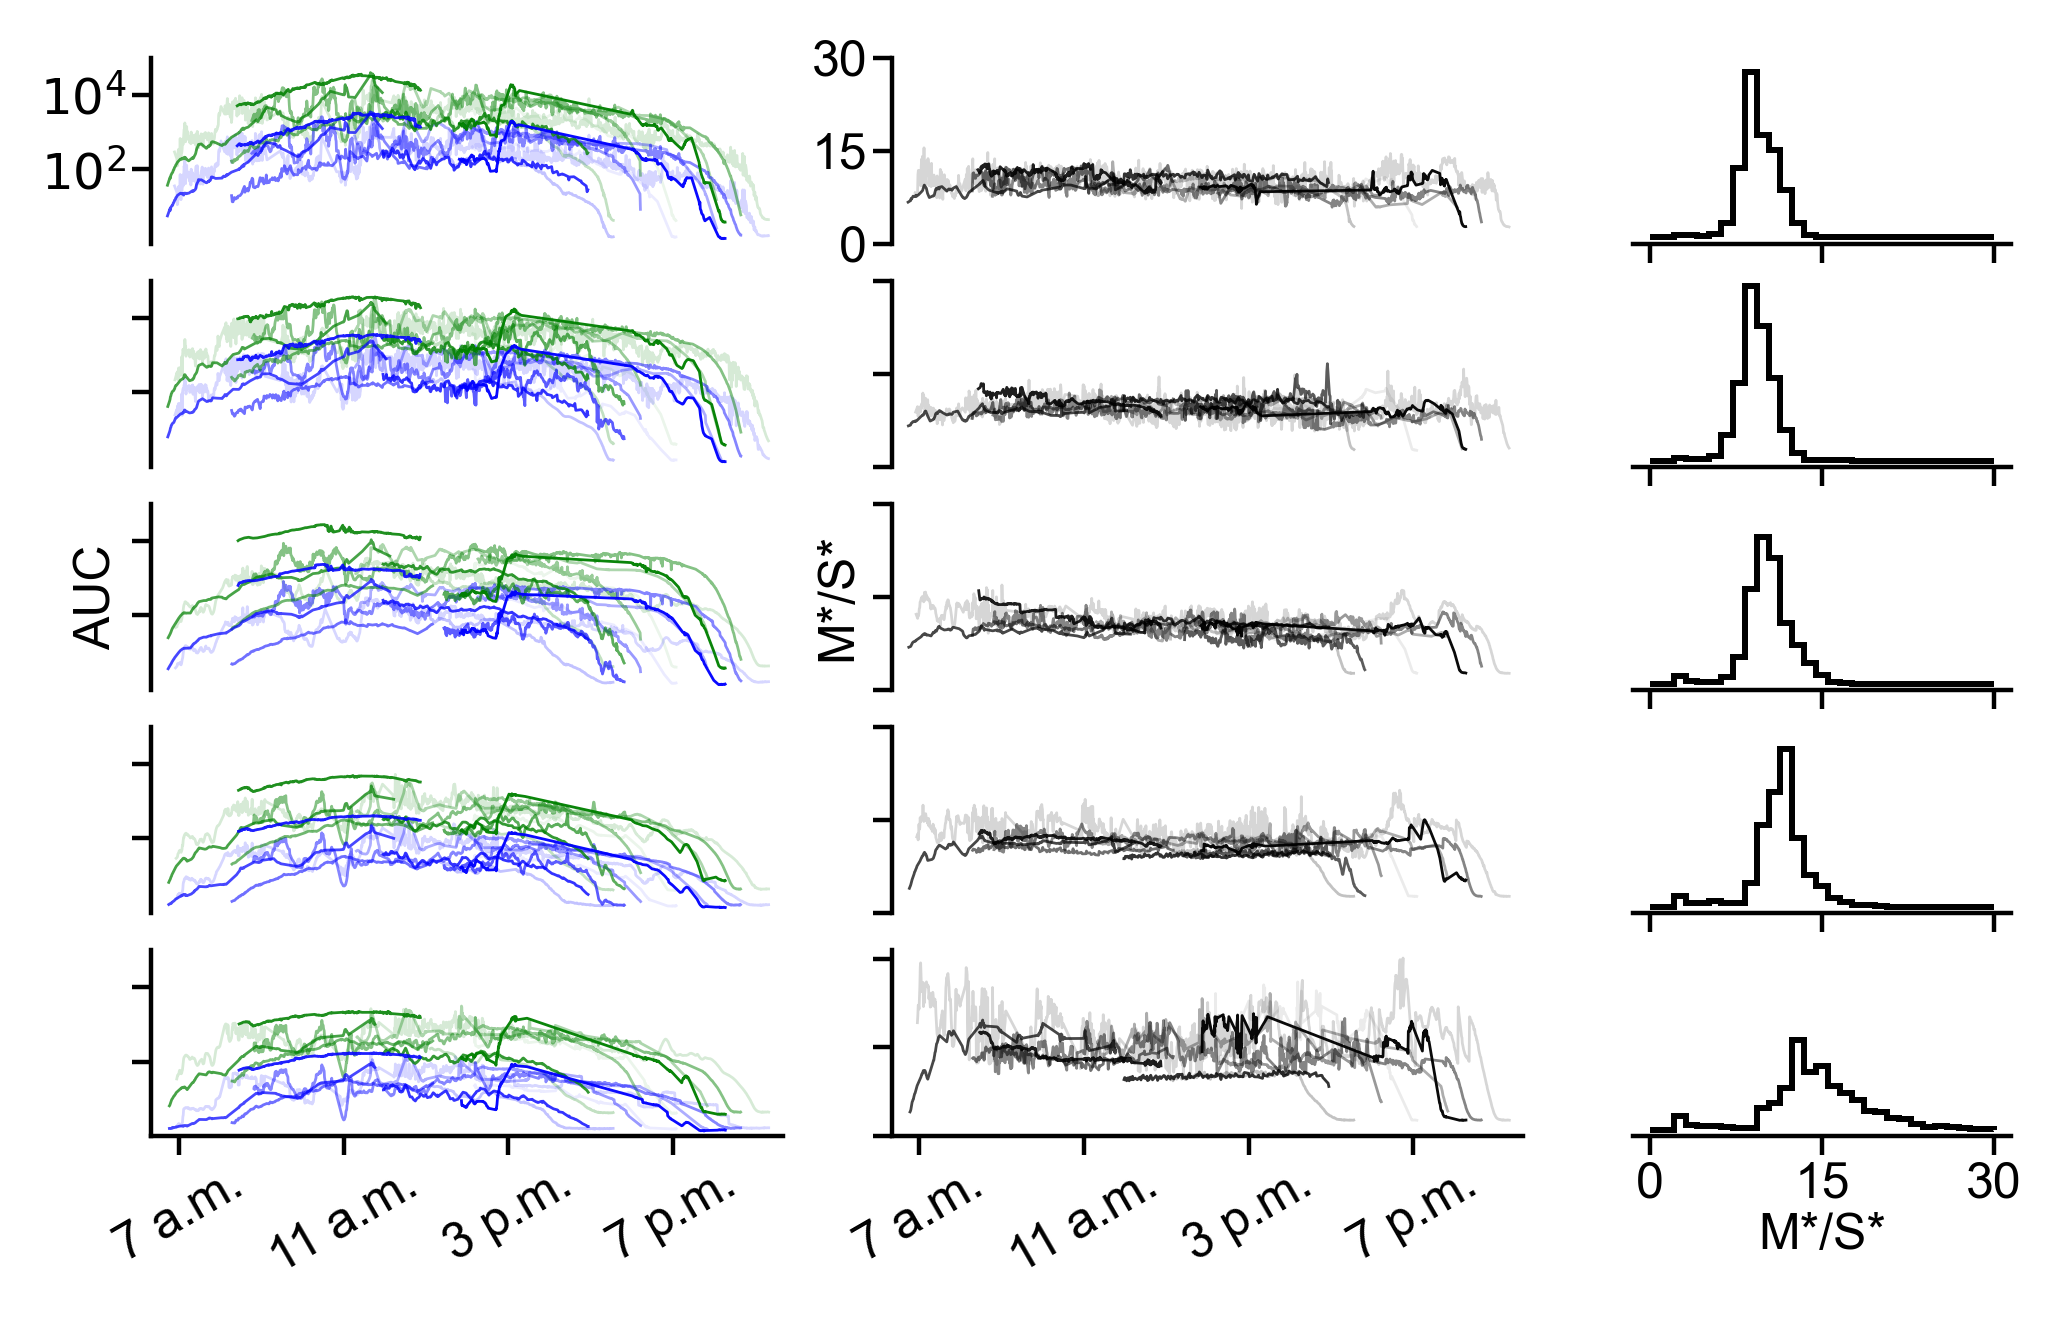

In [12]:
with mpl.rc_context(rc_dict_boxplot):
    fig,axes = plt.subplots(
    5,
    3,
    figsize=(6,3.5),sharex='col',
    gridspec_kw={'width_ratios': [1,1,.6],
                'wspace': 0.2}) # 0-> almost touching
    for tt,motor_tilt in enumerate([18,13,3,-7,-18]):
        df_m_over_s = df_all[df_all['motor_tilt'] == motor_tilt]
        m_over_s_per_tilt = df_m_over_s['auc_m_over_s']
        month_day_combos = df_all[['day', 'month']].drop_duplicates()
        for ii in range(len(month_day_combos)):
            day,month = month_day_combos.iloc[ii]
            df_= df_all[(df_all['day'] == day) & (df_all['month'] == month)& (df_all['motor_tilt'] == motor_tilt)]
            df_sorted = df_.sort_values(by='unix_ts', ascending=False)
            # seconds since midnight
            df_sorted['time_of_day_sec'] = (
                df_sorted['hour'] * 3600 +
                df_sorted['minute'] * 60 +
                df_sorted['second']
            )
            df_sorted['norm_int_auc_s'] = df_sorted['auc_scone']/df_sorted['int_t']
            df_sorted['norm_int_auc_m'] = df_sorted['auc_mcone']/df_sorted['int_t']
            axes[tt,0].plot(df_sorted['time_of_day_sec'],df_sorted['norm_int_auc_m'],color='green',alpha=0.08+0.08*ii)
            axes[tt,0].plot(df_sorted['time_of_day_sec'],df_sorted['norm_int_auc_s'],color='blue',alpha=0.08+0.08*ii)
            axes[tt,0].set_yscale('log')
            axes[tt,0].set_ylim([1, 1e5+1e3])
            axes[tt,0].set_yticks([1e2, 1e4])
            axes[tt,0].set_yticklabels([r'$10^2$', r'$10^4$'])
            
            
            axes[tt,1].plot(df_sorted['time_of_day_sec'],df_sorted['auc_m_over_s'],color='k',alpha=0.08+0.08*ii)
            if tt!=4:
                axes[tt,0].tick_params(bottom=False,labelbottom=False);axes[tt,0].spines['bottom'].set_visible(False)
                axes[tt,1].tick_params(bottom=False,labelbottom=False);axes[tt,1].spines['bottom'].set_visible(False)
            axes[tt,2].hist(m_over_s_per_tilt,bins=bin_edges,color='k',histtype='step');axes[tt,2].set_ylim([-60,1750])
            for col in range(3):
                axes[tt,col].spines['top'].set_visible(False);axes[tt,col].spines['right'].set_visible(False)
                if tt<4:
                    axes[tt,col].tick_params(labelbottom=False)
            
        axes[tt,1].set_yticks([0,15,30]);axes[tt,1].set_yticklabels([0,15,30])
        if tt!=0:
            axes[tt,0].set_yticklabels([])
            axes[tt,1].set_yticklabels([])
        axes[tt,-1].set_yticks([]);axes[tt,-1].set_yticklabels([]);axes[tt,-1].spines['left'].set_visible(False)
    ## time axis for the first two columns
    for col in range(2):
        axes[-1,col].set_xlim([7*3600-2400,21*3600+2400])
        axes[-1,col].set_xticks([ii*3600 for ii in [7,11,15,19]])
        axes[-1,col].set_xticklabels(['7 a.m.','11 a.m.','3 p.m.','7 p.m.'], rotation = 30)
    axes[-1,-1].set_xlabel('M*/S*')
    axes[-1,-1].set_xticks([0,15,30])
    axes[-1,-1].set_xticklabels([0,15,30])
    axes[2,0].set_ylabel('AUC');axes[2,1].set_ylabel('M*/S*')

    #plt.tight_layout()
    plt.savefig('./Fig2D_v02062026.svg')
    #plt.show()